# Control supervisorio: ejemplo introductorio con dos máquinas y un AGV

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nebisman/deslab-py3/blob/main/notebooks/LCS_ejemplo_introductorio_AGV.ipynb)

Este notebook desarrolla con DESlab el ejemplo introductorio de las diapositivas
*Control supervisorio de SEDs descritos por autómatas: especificaciones* (diapositivas 2, 3, 4, 7 y 8).

Consideremos el siguiente sistema (diapositiva 2): la máquina $M_1$ procesa piezas que un vehículo
autónomo (AGV) lleva a la máquina $M_2$; las piezas que termina $M_2$ las lleva el AGV al buffer $B$.

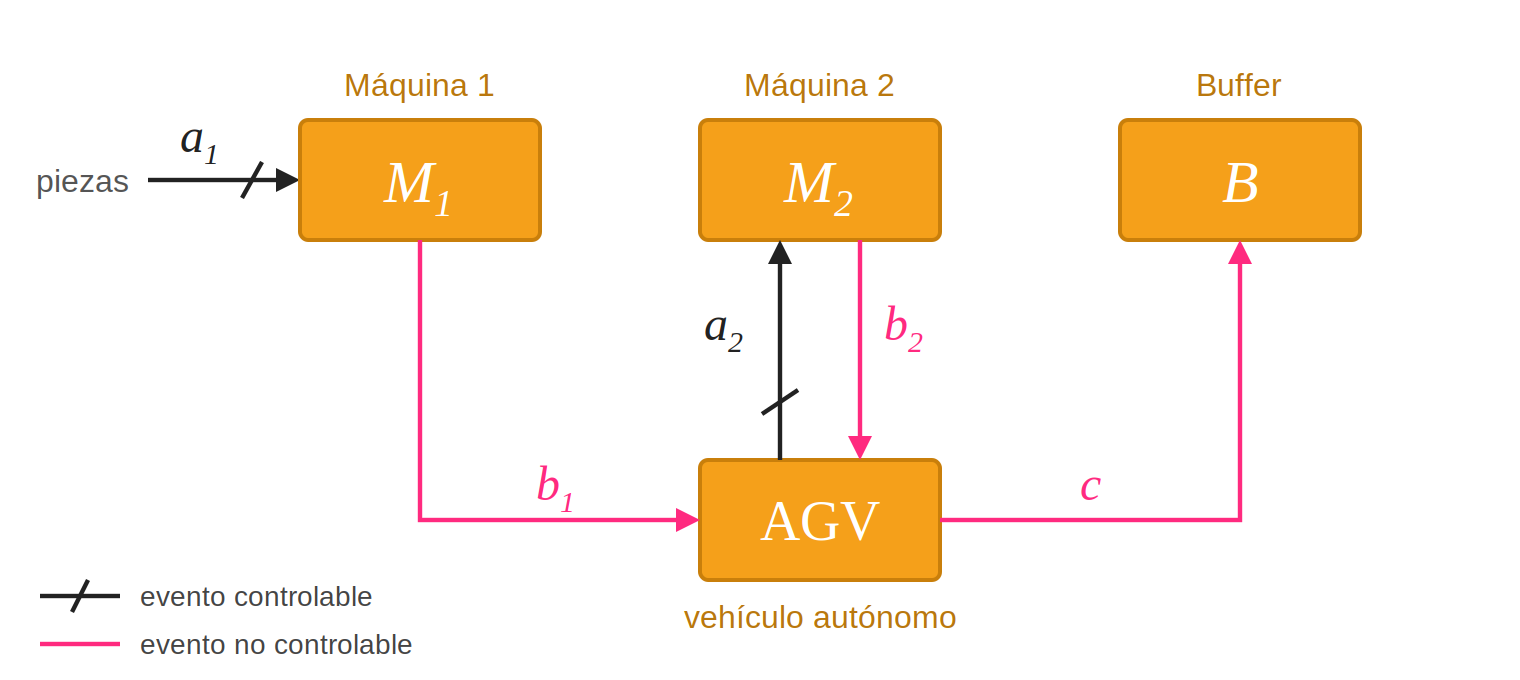

| Evento | Significado | Tipo |
|---|---|---|
| $a_1$ | $M_1$ toma una pieza y empieza a trabajar | controlable |
| $b_1$ | $M_1$ termina y deja la pieza en el AGV | no controlable |
| $a_2$ | $M_2$ toma la pieza del AGV y empieza a trabajar | controlable |
| $b_2$ | $M_2$ termina y deja la pieza en el AGV | no controlable |
| $c$ | el AGV lleva la pieza al buffer $B$ | no controlable |

Como en las diapositivas, los eventos controlables se marcan con una rayita sobre el arco; en la
figura y en los dibujos de DESlab los eventos no controlables van en color rosado.

In [ ]:
#@title Instalación de DESlab desde GitHub (ejecute esta celda primero)
import importlib, json, shutil, subprocess, sys
from importlib.metadata import distribution

# programas de graphviz (Colab normalmente ya los trae instalados)
if shutil.which("dot") is None:
    subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)

%pip install -q networkx graphviz
# se reinstala siempre la última versión de DESlab que está en GitHub
%pip install -q --force-reinstall --no-deps --no-cache-dir git+https://github.com/nebisman/deslab-py3.git

# si la celda se ejecuta de nuevo, DESlab se descarga de la memoria para
# que la siguiente celda importe la versión recién instalada
importlib.invalidate_caches()
for name in [m for m in sys.modules if m == "deslab" or m.startswith("deslab.")]:
    del sys.modules[name]

info = json.loads(distribution("deslab").read_text("direct_url.json") or "{}")
print("DESlab instalado desde el commit", info.get("vcs_info", {}).get("commit_id", "?")[:7])

In [2]:
from deslab import *

## 1. Autómatas del sistema (diapositiva 3)

- $M_1$ y $M_2$ tienen dos estados: $I$ (en reposo, inicial y marcado) y $B$ (trabajando).
- El AGV tiene tres estados: $E$ (vacío, inicial y marcado), $M_1$ (lleva una pieza de $M_1$ que debe
  entregar a $M_2$) y $M_2$ (lleva una pieza de $M_2$ que debe llevar al buffer).

En Python `M1` y `M2` son los autómatas de las máquinas, por eso los estados del AGV se llaman `m1` y
`m2`; la tabla hace que se dibujen como $M_1$ y $M_2$.

**Eventos controlables.** Se indican con el parámetro `Sigcon`, y la composición paralela une los
conjuntos `Sigcon` de los componentes. Si se omite, `fsa` considera *todos* los eventos controlables;
por eso hay que darlo en cada autómata. En el AGV el único evento controlable es $a_2$, que comparte
con $M_2$.

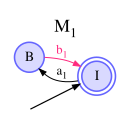

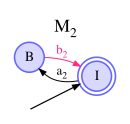

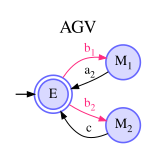

In [ ]:
syms('I B E m1 m2 a1 b1 a2 b2 c')
tabla = [(a1, 'a_1'), (b1, 'b_1'), (a2, 'a_2'), (b2, 'b_2'), (m1, 'M_1'), (m2, 'M_2')]

M1 = fsa([I, B], [a1, b1], [(I, a1, B), (B, b1, I)], [I], [I], tabla,
         Sigcon=[a1], name='$M_1$')
M2 = fsa([I, B], [a2, b2], [(I, a2, B), (B, b2, I)], [I], [I], tabla,
         Sigcon=[a2], name='$M_2$')
AGV = fsa([E, m1, m2], [b1, a2, b2, c],
          [(E, b1, m1), (m1, a2, E), (E, b2, m2), (m2, c, E)], [E], [E], tabla,
          Sigcon=[a2, c], name='AGV')
draw(M1, M2, AGV)

## 2. Sistema sin control $G = M_1 \parallel M_2 \parallel \mathrm{AGV}$ (diapositiva 4)

Los estados de $G$ son las ternas (estado de $M_1$, estado de $M_2$, estado del AGV). Como en la
diapositiva, se renombran con números:

| Estado | $M_1$ | $M_2$ | AGV | | Estado | $M_1$ | $M_2$ | AGV |
|---|---|---|---|---|---|---|---|---|
| 0 | $I$ | $I$ | $E$ | | 5 | $B$ | $B$ | $E$ |
| 1 | $B$ | $I$ | $E$ | | 6 | $I$ | $B$ | $M_1$ |
| 2 | $I$ | $I$ | $M_1$ | | 7 | $B$ | $B$ | $M_1$ |
| 3 | $B$ | $I$ | $M_1$ | | 8 | $I$ | $I$ | $M_2$ |
| 4 | $I$ | $B$ | $E$ | | 9 | $B$ | $I$ | $M_2$ |

Solo el estado 0 es marcado: las dos máquinas en reposo y el AGV vacío.

eventos controlables: ['a1', 'a2', 'c']


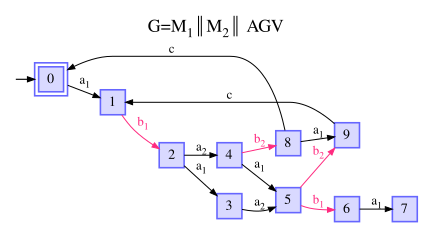

In [36]:
G = M1 // M2 // AGV

# numeración de la diapositiva 4: (M1, M2, AGV) -> número
numeracion = {(I, I, E): 0, (B, I, E): 1, (I, I, m1): 2, (B, I, m1): 3, (I, B, E): 4,
              (B, B, E): 5, (I, B, m1): 6, (B, B, m1): 7, (I, I, m2): 8, (B, I, m2): 9}

G = G.renamestates({((x1, x2), x3): numeracion[(x1, x2, x3)] for ((x1, x2), x3) in G.X})
G = G.setpar(name='$G = M_1 \\parallel M_2 \\parallel$ AGV', style="rectangle")

print('eventos controlables:', sorted(G.Sigcon))
draw(G)

Comprobamos que las transiciones de $G$ son las de la diapositiva 4. `G.Graph` es el grafo de
networkx del autómata: cada arco $(x, y)$ tiene como clave el evento.

In [28]:
T_diapositiva = {(0, a1, 1), (1, b1, 2), (2, a1, 3), (2, a2, 4), (3, a2, 5), (4, a1, 5), (4, b2, 8),
                 (5, b1, 6), (5, b2, 9), (6, a1, 7), (8, a1, 9), (8, c, 0), (9, c, 1)}
T_G = {(x, e, y) for x, y, e in G.Graph.edges(keys=True)}
print('¿G coincide con la diapositiva 4?', T_G == T_diapositiva)

¿G coincide con la diapositiva 4? False


## 3. Especificación y bloqueo (diapositiva 7)

Supongamos que no hay otra especificación: el lenguaje deseado es $K = L_m(G)$, y el supervisor $S$
debe cumplir las condiciones 2 a 4:

2. $S$ no deshabilita eventos no controlables.
3. $S/G$ no tiene bloqueo.
4. $S$ es óptimo, es decir, máximamente permisivo.

$G$ tiene bloqueo. En el estado 7 $(B, B, M_1)$ el AGV lleva una pieza de $M_1$ y $M_2$ está
trabajando: $M_2$ no puede dejar su pieza ($b_2$) porque el AGV está ocupado, el AGV no puede entregar
la pieza ($a_2$) porque $M_2$ está ocupada, y $M_1$ tampoco puede dejar la suya ($b_1$). El estado 6
no es un bloqueo inmediato, pero su único evento, $a_1$, lleva al 7.

`coac(G)` es la parte coaccesible de $G$: los estados desde los que se puede llegar a un estado
marcado. Los demás son bloqueantes; se resaltan en naranja.

estados desde los que no se llega al estado marcado 0: [6, 7]


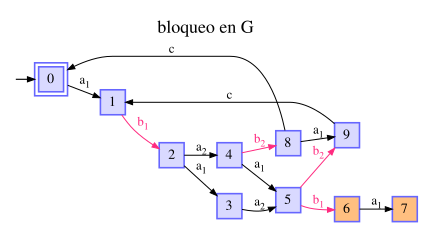

In [37]:
NARANJA = ['orange', 50]   # color de los estados bloqueantes

bloqueantes = G.X - coac(G).X
print('estados desde los que no se llega al estado marcado 0:', sorted(bloqueantes))
draw(G.highlightstates(bloqueantes, color=NARANJA).setpar(name='bloqueo en $G$'))

## 4. Síntesis del supervisor (diapositiva 8)

El supervisor se obtiene quitando estados de $G$ hasta que no quede nada por quitar:

- **estados bloqueantes** (naranja): se quitan con `trim`, que deja la parte accesible y coaccesible;
- **estados que violan controlabilidad** (magenta): aquellos en los que la planta puede ejecutar un
  evento no controlable que ya se quitó; el supervisor no lo puede impedir, así que hay que evitar
  llegar a ese estado.

Cada vez que se quita un estado se pierden las transiciones que llegaban a él, lo que puede crear
nuevos estados bloqueantes o nuevas violaciones de controlabilidad.

**Paso 1.** Quitamos los estados bloqueantes 6 y 7.

en el estado 5 la planta puede ejecutar ['b1'], que no es controlable


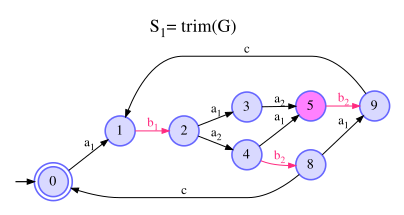

In [38]:
Sigma_uc = G.Sigma - G.Sigcon

def violan_controlabilidad(S):
    """estados de S en los que la planta G puede ejecutar un evento
    no controlable que S ya no tiene"""
    return {x for x in S.X if (G.Gamma(x) & Sigma_uc) - S.Gamma(x)}

S1 = trim(G).setpar(name='$S_1$ = trim($G$)')
violan = violan_controlabilidad(S1)
for x in sorted(violan):
    print(f'en el estado {x} la planta puede ejecutar {sorted((G.Gamma(x) & Sigma_uc) - S1.Gamma(x))}, '
          'que no es controlable')
draw(S1.highlightstates(violan))

Al quitar el estado 6 desaparece la transición $5 \xrightarrow{b_1} 6$. Pero $b_1$ no es controlable:
el supervisor no puede impedir que $M_1$ termine, así que debe evitar llegar al estado 5. Para eso
deshabilita los eventos controlables que llevan a él: $a_2$ en el estado 3 y $a_1$ en el estado 4.

**Paso 2.** Quitamos el estado 5.

nuevos estados bloqueantes: [3]


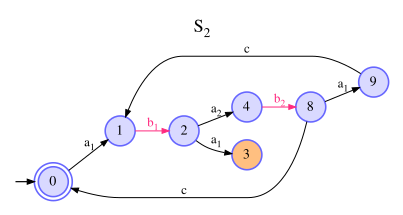

In [39]:
S2 = S1
for x in violan:
    S2 = S2.deletestate(x)
S2 = S2.setpar(name='$S_2$')

bloqueantes = S2.X - coac(S2).X
print('nuevos estados bloqueantes:', sorted(bloqueantes))
draw(S2.highlightstates(bloqueantes, color=NARANJA))

Este es el autómata de la diapositiva 8, donde los estados 8 y 9 aparecen numerados como 5 y 6.
El estado 3 quedó bloqueado: su único evento era $a_2$ hacia el estado 5.

**Paso 3.** Quitamos el estado 3 y revisamos otra vez la controlabilidad.

estados que violan controlabilidad: []
estados bloqueantes:                []


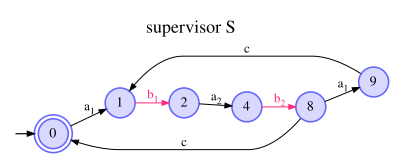

In [40]:
S = trim(S2).setpar(name='supervisor $S$')
print('estados que violan controlabilidad:', sorted(violan_controlabilidad(S)))
print('estados bloqueantes:               ', sorted(S.X - coac(S).X))
draw(S)

Al quitar el estado 3 se deshabilita $a_1$ en el estado 2, lo que está permitido porque $a_1$ es
controlable. Ya no hay estados bloqueantes ni violaciones de controlabilidad, así que $S$ es el
supervisor.

## 5. Verificación de las condiciones 2 a 4

`supcontrollable(G, G)` calcula directamente el supremo sublenguaje controlable de $K = L_m(G)$, es
decir, el supervisor máximamente permisivo. Debe coincidir con el $S$ obtenido paso a paso.

In [ ]:
SUP = supcontrollable(S, G)

print('2. ¿S no deshabilita eventos no controlables?', iscontrollable(S, G))
print('3. ¿S/G no tiene bloqueo?                    ', S == trim(S))
draw()

2. ¿S no deshabilita eventos no controlables? True
3. ¿S/G no tiene bloqueo?                     True
4. ¿S coincide con supcontrollable(G, G)?     True


**Acción de control.** En cada estado, el supervisor deshabilita los eventos que la planta puede
ejecutar pero que $S$ no tiene:

In [11]:
for x in sorted(S.X):
    deshabilitados = G.Gamma(x) - S.Gamma(x)
    if deshabilitados:
        print(f'en el estado {x} el supervisor deshabilita {sorted(deshabilitados)}')

en el estado 2 el supervisor deshabilita ['a1']
en el estado 4 el supervisor deshabilita ['a1']


El supervisor solo actúa sobre $a_1$: $M_1$ no puede tomar una pieza nueva mientras el AGV lleva la
pieza que ella terminó (estado 2), ni mientras $M_2$ está trabajando (estado 4). Así $M_1$ nunca
termina una pieza cuando el AGV no la puede recibir, y el sistema no se bloquea.